In [ ]:
#import
import numpy as np
import pandas as pd
from ucimlrepo import fetch_ucirepo

Putri Tajudin (24/535824/TK/59469)
Zahra Elfatima (24/535709/TK/59448)

In [ ]:
#loading the dataset
data = fetch_ucirepo(id=45)

X = data.data.features
y = data.data.targets

display(X)
display(y)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,45,1,1,110,264,0,0,132,0,1.2,2,0.0,7.0
299,68,1,4,144,193,1,0,141,0,3.4,2,2.0,7.0
300,57,1,4,130,131,0,0,115,1,1.2,2,1.0,7.0
301,57,0,2,130,236,0,2,174,0,0.0,2,1.0,3.0


,num
0,0
1,2
2,1
3,0
4,0
...,...
298,1
299,2
300,3
301,1


In [ ]:
# split data
selected_features = ['age', 'trestbps', 'chol', 'thalach']
X_filtered = X[selected_features]

print("--- 5 Data Teratas Fitur Pilihan ---")
print(X_filtered.head())

print("\n--- Ringkasan Statistik ---")
print(X_filtered.describe())

--- 5 Data Teratas Fitur Pilihan ---
   age  trestbps  chol  thalach
0   63       145   233      150
1   67       160   286      108
2   67       120   229      129
3   37       130   250      187
4   41       130   204      172

--- Ringkasan Statistik ---
              age    trestbps        chol     thalach
count  303.000000  303.000000  303.000000  303.000000
mean    54.438944  131.689769  246.693069  149.607261
std      9.038662   17.599748   51.776918   22.875003
min     29.000000   94.000000  126.000000   71.000000
25%     48.000000  120.000000  211.000000  133.500000
50%     56.000000  130.000000  241.000000  153.000000
75%     61.000000  140.000000  275.000000  166.000000
max     77.000000  200.000000  564.000000  202.000000


In [ ]:
# Cek missing values
print("Data Kosong per Kolom:")
print(X_filtered.isnull().sum())

# Cek data
display(X_filtered)


Data Kosong per Kolom:
age         0
trestbps    0
chol        0
thalach     0
dtype: int64


,age,trestbps,chol,thalach
0,63,145,233,150
1,67,160,286,108
2,67,120,229,129
3,37,130,250,187
4,41,130,204,172
...,...,...,...,...
298,45,110,264,132
299,68,144,193,141
300,57,130,131,115
301,57,130,236,174


In [ ]:
# 1. Pastikan target hanya berisi 0 dan 1
# Jika nilai > 0, ubah jadi 1. Jika 0, tetap 0.
y_binary = np.where(y > 0, 1, 0)

# 2. Cek jumlah masing-masing kelas dalam target
unique, counts = np.unique(y_binary, return_counts=True)
print("Distribusi Target (0 = Sehat, 1 = Sakit):")
print(dict(zip(unique, counts)))

# 3. Ubah X_filtered menjadi NumPy array agar siap diproses secara matematis
X_array = X_filtered.to_numpy()

print("\nBentuk data X:", X_array.shape)
print("Bentuk data y:", y_binary.shape)

Distribusi Target (0 = Sehat, 1 = Sakit):
{np.int64(0): np.int64(164), np.int64(1): np.int64(139)}

Bentuk data X: (303, 4)
Bentuk data y: (303, 1)


In [ ]:
# data split
# Mengacak data agar distribusinya merata
indices = np.arange(len(X_array))
np.random.seed(42) # Agar hasil acakan selalu sama setiap kali dijalankan
np.random.shuffle(indices)

train_size = int(0.8 * len(X_array))
train_idx, test_idx = indices[:train_size], indices[train_size:]

# Membagi data mentah (sebelum di-scale)
X_train_raw = X_array[train_idx]
X_test_raw = X_array[test_idx]
y_train = y_binary[train_idx]
y_test = y_binary[test_idx]

In [ ]:
# normalisasi data
def manual_scaler_fit_transform(train_data, test_data):
    # Cari Min dan Max hanya dari data Training
    min_val = np.min(train_data, axis=0)
    max_val = np.max(train_data, axis=0)

    # Cek potensi division by zero, jika min == max (fitur konstan)
    diff = max_val - min_val
    if np.any(diff == 0):
        print("Warning: Ada fitur dengan nilai konstan (min == max). Scaling dilewati untuk fitur tersebut.")
        # Untuk fitur konstan, set scaled ke 0 (atau bisa ke mean, tapi 0 sederhana)
        diff = np.where(diff == 0, 1, diff)  # Hindari /0 dengan set diff=1 untuk konstan

    # Transformasi data Training
    train_scaled = (train_data - min_val) / diff

    # Transformasi data Test (memakai min/max dari Training)
    # Untuk mencegah Data Leakage dari test ke train, tetap pakai min/max dari train untuk scaling test
    test_scaled = (test_data - min_val) / diff

    return train_scaled, test_scaled

# Jalankan fungsi scaler
X_train, X_test = manual_scaler_fit_transform(X_train_raw, X_test_raw)

In [ ]:
# 1. Fungsi Sigmoid yaitu mengubah angka (z) menjadi probabilitas (0 sampai 1)
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# 2. Fungsi Utama untuk training (Gradient Descent)
def train_model(X, y, learning_rate=0.1, iterations=3000):
    m, n = X.shape # m = jumlah data, n = jumlah fitur (4)

    # Inisialisasi awal, Bobot (W) dan Bias (b) dimulai dari nol
    weights = np.zeros((n, 1))
    bias = 0

    # List untuk mencatat history dari error agar bisa dibuat grafiknya nanti
    loss_history = []

    for i in range(iterations):
        # FORWARD PROPAGATION
        # Menghitung prediksi linearyaitu z = X.W + b
        z = np.dot(X, weights) + bias
        y_pred = sigmoid(z)

        # COST FUNCTION (LOG LOSS)
        # Menghitung seberapa jauh kesalahan model saat ini
        # epsilon (1e-15) ditambah agar tidak terjadi log(0) yang error
        loss = - (1/m) * np.sum(y * np.log(y_pred + 1e-15) + (1-y) * np.log(1-y_pred + 1e-15))
        loss_history.append(loss)

        # BACKWARD PROPAGATION (GRADIENT DESCENT)
        # Mencari arah perubahan (turunan) untuk memperbaiki W dan b
        dw = (1/m) * np.dot(X.T, (y_pred - y))
        db = (1/m) * np.sum(y_pred - y)

        # UPDATE PARAMETERS
        # Memperbaiki nilai W dan b berdasarkan learning rate
        weights -= learning_rate * dw
        bias -= learning_rate * db

    return weights, bias, loss_history

# 3. Jalankan Pelatihan Model
# melakukan pengulangan (iterations) agar model cukup pintar
W, b, history = train_model(X_train, y_train, learning_rate=0.01, iterations=7000)


print("Bobot (Weights) akhir:\n", W)
print("Bias akhir:", b)

Bobot (Weights) akhir:
 [[ 0.87088959]
 [ 0.45652266]
 [ 0.38369952]
 [-1.92459721]]
Bias akhir: 0.24897108990444497


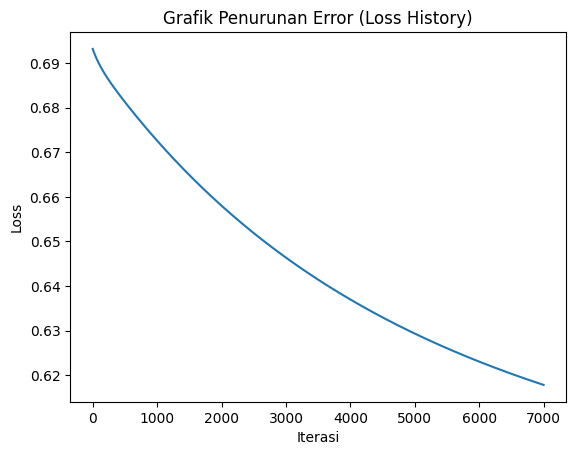

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history)
plt.title("Grafik Penurunan Error (Loss History)")
plt.xlabel("Iterasi")
plt.ylabel("Loss")
plt.show()


In [ ]:
# 1. Fungsi Prediksi
def predict(X, weights, bias):
    z = np.dot(X, weights) + bias
    probabilities = sigmoid(z)
    # Jika probabilitas >= 0.5, diklasifikasikan sebagai 1 (Sakit)
    return np.array([1 if p >= 0.5 else 0 for p in probabilities]).reshape(-1, 1)

# 2. Eksekusi Prediksi pada Data Testing
y_pred = predict(X_test, W, b)

# Lihat 10 prediksi pertama dengan jawaban aslinya
print("Prediksi Model vs Jawaban Asli (10 Data Pertama):")
for i in range(10):
    status_pred = "Sakit" if y_pred[i] == 1 else "Sehat"
    status_asli = "Sakit" if y_test[i] == 1 else "Sehat"
    print(f"Data ke-{i+1}: Prediksi = {status_pred} | Asli = {status_asli}")

Prediksi Model vs Jawaban Asli (10 Data Pertama):
Data ke-1: Prediksi = Sehat | Asli = Sehat
Data ke-2: Prediksi = Sehat | Asli = Sakit
Data ke-3: Prediksi = Sehat | Asli = Sehat
Data ke-4: Prediksi = Sakit | Asli = Sakit
Data ke-5: Prediksi = Sakit | Asli = Sehat
Data ke-6: Prediksi = Sakit | Asli = Sakit
Data ke-7: Prediksi = Sehat | Asli = Sehat
Data ke-8: Prediksi = Sehat | Asli = Sehat
Data ke-9: Prediksi = Sehat | Asli = Sakit
Data ke-10: Prediksi = Sehat | Asli = Sehat


In [ ]:
# Hitung elemen Confusion Matrix
tp = np.sum((y_pred == 1) & (y_test == 1)) # True Positive
tn = np.sum((y_pred == 0) & (y_test == 0)) # True Negative
fp = np.sum((y_pred == 1) & (y_test == 0)) # False Positive
fn = np.sum((y_pred == 0) & (y_test == 1)) # False Negative

# Hitung Metrics
accuracy = (tp + tn) / len(y_test)
precision = tp / (tp + fp) if (tp + fp) > 0 else 0
recall = tp / (tp + fn) if (tp + fn) > 0 else 0
f1_score = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

print("\nPERFORMANCE METRICS")
print(f"Accuracy : {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall   : {recall * 100:.2f}%")
print(f"F1-Score : {f1_score * 100:.2f}%")


PERFORMANCE METRICS
Accuracy : 73.77%
Precision: 69.57%
Recall   : 64.00%
F1-Score : 66.67%


In [ ]:
def k_fold_cross_validation(X, y, k=5, lr=0.1, iters=1000):
    n_samples = X.shape[0]
    fold_size = n_samples // k
    indices = np.arange(n_samples)
    np.random.shuffle(indices) # Acak data sebelum dibagi

    accuracies = []

    for i in range(k):
        # 1. Tentukan indeks untuk Testing dan Training pada fold ini
        test_indices = indices[i * fold_size : (i + 1) * fold_size]
        train_indices = np.concatenate([indices[:i * fold_size], indices[(i + 1) * fold_size:]])

        # 2. Ambil data mentah (sebelum di-scale)
        X_train_raw, X_test_raw = X[train_indices], X[test_indices]
        y_train, y_test = y[train_indices], y[test_indices]

        # 3. Scaling data menggunakan min-max scaler manual
        # Hitung min/max hanya dari data training
        min_train = np.min(X_train_raw, axis=0)
        max_train = np.max(X_train_raw, axis=0)

        # Terapkan scaling ke train dan test menggunakan parameter training
        X_train_fold = (X_train_raw - min_train) / (max_train - min_train)
        X_test_fold = (X_test_raw - min_train) / (max_train - min_train)

        # 4. Training Model
        W_fold, b_fold, _ = train_model(X_train_fold, y_train, learning_rate=lr, iterations=iters)

        # 5. Evaluasi pada data test
        y_pred_fold = predict(X_test_fold, W_fold, b_fold)
        acc = np.sum(y_pred_fold == y_test) / len(y_test)
        accuracies.append(acc)

        print(f"Fold {i+1}: Accuracy = {acc*100:.2f}%")

    print(f"\nAverage K-Fold Accuracy: {np.mean(accuracies)*100:.2f}%")
    return accuracies

# Jalankan K-Fold (Gunakan X_array yang belum di-scale)
# Bagi jadi 5 lipatan (5-Fold)
kfold_results = k_fold_cross_validation(X_array, y_binary, k=5, lr=0.5, iters=3000)

Fold 1: Accuracy = 70.00%
Fold 2: Accuracy = 71.67%
Fold 3: Accuracy = 73.33%
Fold 4: Accuracy = 73.33%
Fold 5: Accuracy = 63.33%

Average K-Fold Accuracy: 70.33%


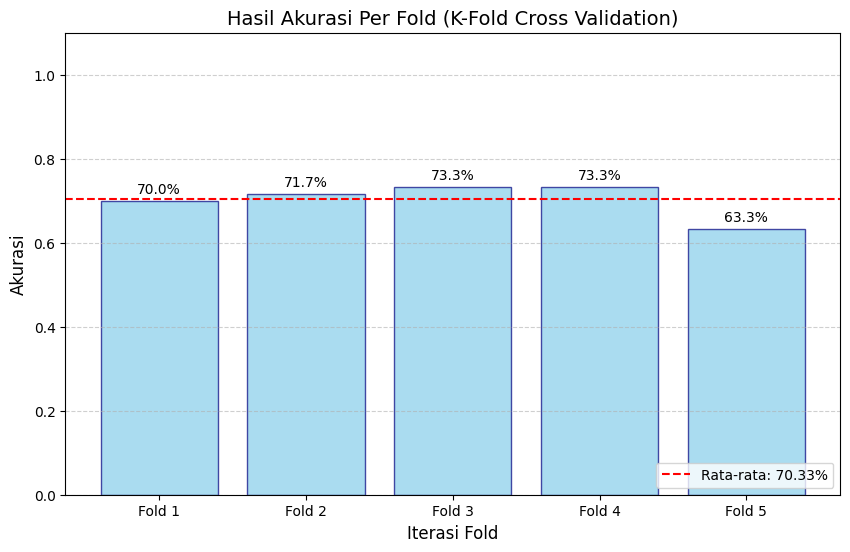

In [ ]:
import matplotlib.pyplot as plt

def plot_kfold_results(accuracies):
    # Membuat list label untuk sumbu X (Fold 1, Fold 2, dst)
    folds = [f"Fold {i+1}" for i in range(len(accuracies))]

    # Hitung rata-rata untuk garis referensi
    avg_acc = np.mean(accuracies)

    plt.figure(figsize=(10, 6))

    # Membuat Bar Chart
    bars = plt.bar(folds, accuracies, color='skyblue', edgecolor='navy', alpha=0.7)

    # Menambahkan garis rata-rata (Average)
    plt.axhline(y=avg_acc, color='red', linestyle='--', label=f'Rata-rata: {avg_acc*100:.2f}%')

    # Menambahkan label angka di atas setiap bar
    for bar in bars:
        yval = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, yval + 0.01, f'{yval*100:.1f}%', ha='center', va='bottom')

    plt.title('Hasil Akurasi Per Fold (K-Fold Cross Validation)', fontsize=14)
    plt.xlabel('Iterasi Fold', fontsize=12)
    plt.ylabel('Akurasi', fontsize=12)
    plt.ylim(0, 1.1)  # Memberikan ruang di atas bar (skala 0-1)
    plt.grid(axis='y', linestyle='--', alpha=0.6)
    plt.legend(loc='lower right')

    plt.show()

# Panggil fungsi visualisasi setelah menjalankan k_fold_cross_validation
plot_kfold_results(kfold_results)